In [7]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [16]:
df=pd.read_csv("data/results.csv")
df.columns=df.columns.str.lower().str.replace(" ","_")
df.head()

,unnamed:_0,date_name,local_team_id,local_team,local_result,visitor_result,visitor_team,visitor_team_id
0,0,Nacional 1976 - Grupo C,1,All Boys,2,0,Aldosivi,0
1,1,Nacional 1976 - Grupo C,0,Aldosivi,4,0,All Boys,1
2,2,Superliga 2019/20 - Fecha 2,0,Aldosivi,0,0,Argentinos,7
3,3,Superliga 2018/19 - Fecha 15,7,Argentinos,1,2,Aldosivi,0
4,4,Torneo 2016 - Fecha 2,0,Aldosivi,3,2,Argentinos,7


In [18]:
df.columns

Index(['unnamed:_0', 'date_name', 'local_team_id', 'local_team',
       'local_result', 'visitor_result', 'visitor_team', 'visitor_team_id'],
      dtype='str')

In [20]:
categorical=['date_name','local_team','visitor_team']
numeric=['local_result','visitor_result']

In [15]:
if (df.isna().sum().sum() == 0):
    print('No contiene elementos nulos')
else:
    print(df.isna().sum())

No contiene elementos nulos


In [24]:
#Queremos extraer el año de la columna date_name, usamos una funcion
def extraer_año(tournament_name):
    import re
    # Buscar cualquier secuencia de cuatro dígitos en el nombre del torneo
    coinc = re.search(r'\d{4}', tournament_name)
    if coinc:
        return coinc.group()
    else:
        return None


In [25]:
df['anio'] = pd.to_numeric(df['date_name'].apply(extraer_año))

In [28]:
#Agregamos columna de empate o victoria (local o visitante)
condiciones=[df['local_result']<df['visitor_result'],df['local_result']==df['visitor_result'],df['local_result']>df['visitor_result']]
resultados=['Victoria visitante','Empate','Victoria local']
df['victoria']=np.select(condiciones,resultados,default="NS")

In [ ]:
#Agregamos goles totales y diferencia de goles
df['goles']=df['local_result']+df['visitor_result']
df['diferencia_goles']=(df['local_result']-df['visitor_result']).abs()

<Axes: xlabel='goles', ylabel='Count'>

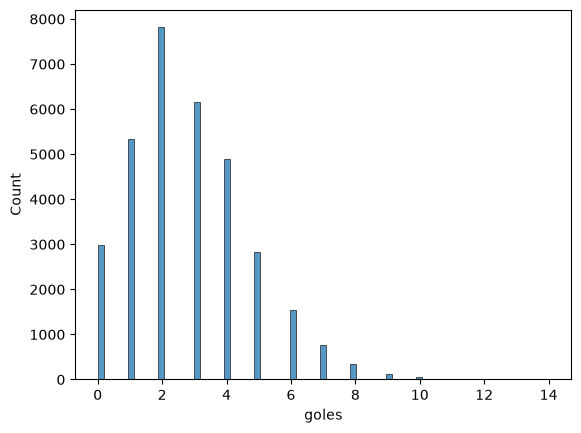

In [41]:
sns.histplot(df,x='goles')

<Axes: xlabel='diferencia_goles', ylabel='Count'>

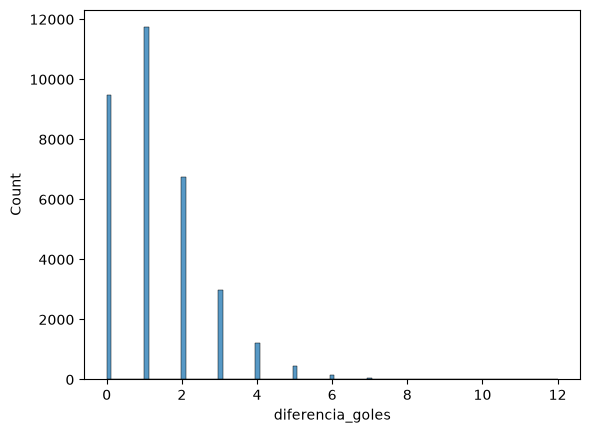

In [40]:
sns.histplot(df,x='diferencia_goles')

<Axes: xlabel='resultado', ylabel='Count'>

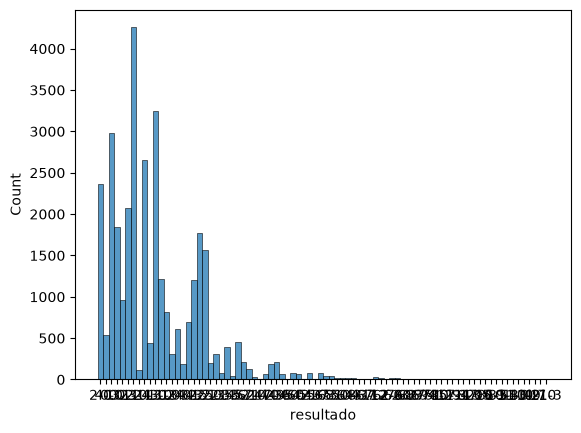